<a href="https://colab.research.google.com/github/Techy-A/Stock-Market-Prediction-Analysis/blob/main/Stock_Market_BiLSTM_Prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#  Stock Market Direction Prediction using ML & BiLSTM

> *"The stock market is a device for transferring money from the impatient to the patient."*  
> — Warren Buffett

---

##  What this notebook does (in plain English)

Think of this as a well-organised science fair project — except instead of baking soda volcanoes, we're trying to outsmart Wall Street.  
We pull **5 years of real stock data**, squeeze **50+ features** out of it (technical indicators, volatility signals, lag patterns), then throw **three different ML models** at the problem and let them fight it out.  
Finally, we do a proper **backtest** — because a model that looks great on paper but loses money in practice is just an expensive disappointment.

---

> *"Any fool can write code that a computer can understand. Good code is written so that humans can understand it."*  
> — Martin Fowler

---

In [1]:
# ============================================================
#  CELL 1 — Install & Import Everything We'll Need
# ============================================================
# "Before anything else, preparation is the key to success."
#                                          — Alexander Graham Bell
#
# We install yfinance (Yahoo Finance data), ta (technical analysis),
# xgboost, and shap (for model explainability).
# Everything else — sklearn, tensorflow, pandas — is pre-loaded in Colab.

!pip install yfinance ta xgboost shap --quiet

import warnings
warnings.filterwarnings('ignore')

# --- Core ---
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
from datetime import datetime, timedelta

# --- Data ---
import yfinance as yf
import ta

# --- Machine Learning ---
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler, RobustScaler
from sklearn.metrics import (classification_report, confusion_matrix,
                             roc_auc_score, f1_score, precision_score,
                             recall_score, roc_curve)
from sklearn.model_selection import TimeSeriesSplit
from sklearn.pipeline import Pipeline
from xgboost import XGBClassifier

# --- Deep Learning ---
import tensorflow as tf
from tensorflow.keras.models import Sequential, Model
from tensorflow.keras.layers import (LSTM, Bidirectional, Dense, Dropout,
                                     BatchNormalization, Input, Concatenate)
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from tensorflow.keras.optimizers import Adam

# --- Explainability ---
import shap

# Style settings — because beautiful charts deserve good-looking defaults
plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette('husl')
pd.set_option('display.float_format', '{:.4f}'.format)
pd.set_option('display.max_columns', 60)

print(f"TensorFlow version : {tf.__version__}")
print(f"GPU detected       : {tf.config.list_physical_devices('GPU')}")
print("All libraries loaded successfully!")

TensorFlow version : 2.19.0
GPU detected       : [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
All libraries loaded successfully!


In [2]:
# ============================================================
#  CELL 2 — Configuration: Change These to Suit Your Needs
# ============================================================
# "The beginning of wisdom is the definition of terms."
#                                          — Socrates
#
# This is your single control panel. Everything downstream reads from here.
# Swap TICKER to 'TSLA', 'GOOGL', 'RELIANCE.NS', '^NSEI', etc.

# ── Stock Selection ──────────────────────────────────────────
TICKER     = 'AAPL'          # Try: 'TSLA', 'MSFT', 'GOOGL', '^NSEI', 'RELIANCE.NS'
START_DATE = '2019-01-01'    # Five years of history
END_DATE   = datetime.today().strftime('%Y-%m-%d')

# ── Model Settings ───────────────────────────────────────────
SEQUENCE_LEN    = 60     # How many past days BiLSTM looks at (the 'memory window')
TEST_SPLIT      = 0.15   # 15% of data is the holdout test set
VAL_SPLIT       = 0.10   # 10% of training data for validation
RANDOM_STATE    = 42     # Because 42 is always the answer
N_SPLITS        = 5      # TimeSeriesSplit folds

# ── BiLSTM Hyperparams ───────────────────────────────────────
LSTM_UNITS      = 128
DROPOUT_RATE    = 0.3
LEARNING_RATE   = 0.001
BATCH_SIZE      = 64
MAX_EPOCHS      = 100    # EarlyStopping will kick in before this, usually

# ── Backtesting ──────────────────────────────────────────────
INITIAL_CAPITAL = 100_000   # Starting capital in USD
TRADING_DAYS    = 252       # Standard trading days per year

print(f"Ticker       : {TICKER}")
print(f"Period       : {START_DATE} → {END_DATE}")
print(f"LSTM Window  : {SEQUENCE_LEN} days")
print(f"Capital      : ${INITIAL_CAPITAL:,}")

Ticker       : AAPL
Period       : 2019-01-01 → 2026-04-08
LSTM Window  : 60 days
Capital      : $100,000


⬇️  Downloading AAPL data from Yahoo Finance...


[*********************100%***********************]  1 of 1 completed



  AAPL — Dataset Overview
  Rows          : 1,825
  Date Range    : 2019-01-02 → 2026-04-07
  Missing Vals  : 0
Price         Close     High      Low     Open    Volume
Date                                                    
2026-03-31 253.7900 255.4800 247.1000 247.9100  49598100
2026-04-01 255.6300 256.1800 253.3300 254.0800  40059400
2026-04-02 255.9200 256.1300 250.6500 254.2000  31289400
2026-04-06 258.8600 262.1600 256.4600 256.5100  29329900
2026-04-07 253.5000 256.2000 245.7000 256.1600  61377300


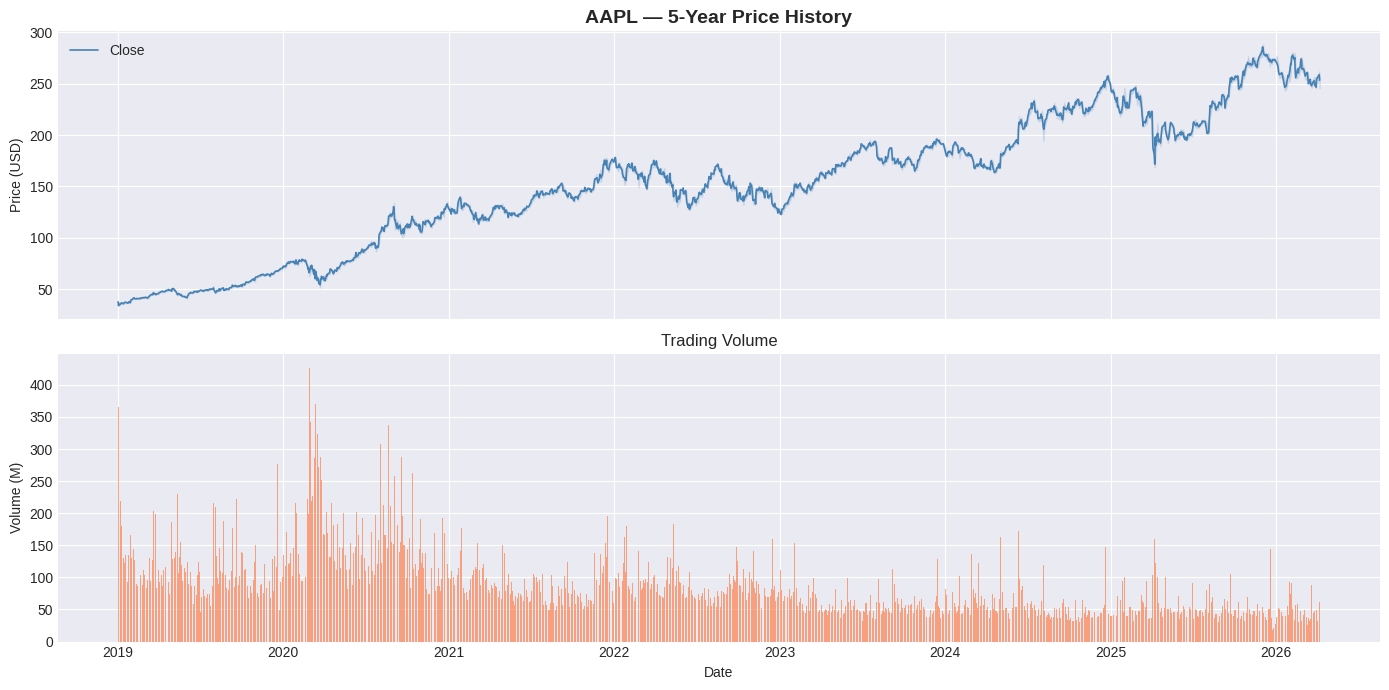

Raw data loaded and visualised.


In [3]:
# ============================================================
#  CELL 3 — Data Download & Sanity Check
# ============================================================
# "Data is the new oil — but like oil, it needs to be refined
#  before it becomes useful."
#                          — Clive Humby (mathematician, Tesco Clubcard creator)
#
# We pull OHLCV data directly from Yahoo Finance via yfinance.
# Then we do a quick health check — missing values, dtypes, shape.
# Never skip this step. Ever.

print(f"⬇️  Downloading {TICKER} data from Yahoo Finance...")
raw_df = yf.download(TICKER, start=START_DATE, end=END_DATE, auto_adjust=True)

# Flatten MultiIndex columns if they exist (yfinance quirk)
if isinstance(raw_df.columns, pd.MultiIndex):
    raw_df.columns = raw_df.columns.get_level_values(0)

raw_df.index = pd.to_datetime(raw_df.index)
raw_df.sort_index(inplace=True)

print(f"\n{'='*55}")
print(f"  {TICKER} — Dataset Overview")
print(f"{'='*55}")
print(f"  Rows          : {len(raw_df):,}")
print(f"  Date Range    : {raw_df.index[0].date()} → {raw_df.index[-1].date()}")
print(f"  Missing Vals  : {raw_df.isnull().sum().sum()}")
print(f"{'='*55}")
print(raw_df.tail(5))

# ── Quick candlestick-style summary plot ─────────────────────
fig, axes = plt.subplots(2, 1, figsize=(14, 7), sharex=True)

axes[0].plot(raw_df.index, raw_df['Close'], color='steelblue', linewidth=1.2, label='Close')
axes[0].fill_between(raw_df.index, raw_df['Low'], raw_df['High'], alpha=0.15, color='steelblue')
axes[0].set_title(f'{TICKER} — 5-Year Price History', fontsize=14, fontweight='bold')
axes[0].set_ylabel('Price (USD)')
axes[0].legend()

axes[1].bar(raw_df.index, raw_df['Volume'] / 1e6, color='coral', alpha=0.7, width=1)
axes[1].set_ylabel('Volume (M)')
axes[1].set_xlabel('Date')
axes[1].set_title('Trading Volume', fontsize=12)

plt.tight_layout()
plt.savefig('price_history.png', dpi=150, bbox_inches='tight')
plt.show()
print("Raw data loaded and visualised.")

In [4]:
# ============================================================
#  CELL 4 — Feature Engineering: Building the 50+ Feature Set
# ============================================================
# "Feature engineering is the art of turning raw data into
#  the language your model actually speaks."
#                               — A frustrated data scientist, somewhere
#
# We create features across five categories:
#   1. Price-derived (returns, log returns, price ratios)
#   2. Trend indicators (SMA, EMA, MACD)
#   3. Momentum indicators (RSI, Stochastic, Williams %R, ROC)
#   4. Volatility indicators (Bollinger Bands, ATR, Keltner, Donchian)
#   5. Lag & rolling features (autocorrelation, cross-feature interactions)
#
# Target: binary direction — 1 if tomorrow's close > today's close, else 0.

def engineer_features(df: pd.DataFrame) -> pd.DataFrame:
    """
    Full feature engineering pipeline.
    Input  : raw OHLCV DataFrame
    Output : feature-rich DataFrame with 50+ columns
    """
    d = df.copy()
    close  = d['Close']
    high   = d['High']
    low    = d['Low']
    volume = d['Volume']
    open_  = d['Open']

    # ── 1. Returns & Price Ratios ─────────────────────────────
    # "Price is what you pay. Value is what you get." — Warren Buffett
    d['return_1d']      = close.pct_change(1)
    d['return_2d']      = close.pct_change(2)
    d['return_5d']      = close.pct_change(5)
    d['return_10d']     = close.pct_change(10)
    d['return_21d']     = close.pct_change(21)
    d['log_return_1d']  = np.log(close / close.shift(1))
    d['log_return_5d']  = np.log(close / close.shift(5))
    d['hl_ratio']       = (high - low) / close          # High-Low spread
    d['co_ratio']       = (close - open_) / open_       # Close vs Open drift
    d['gap']            = (open_ - close.shift(1)) / close.shift(1)  # Overnight gap

    # ── 2. Trend Indicators ───────────────────────────────────
    # Simple & Exponential Moving Averages and crossovers
    for w in [5, 10, 20, 50, 100, 200]:
        d[f'sma_{w}']       = close.rolling(w).mean()
        d[f'ema_{w}']       = close.ewm(span=w, adjust=False).mean()
        d[f'close_vs_sma{w}'] = (close - d[f'sma_{w}']) / d[f'sma_{w}']

    # MACD — the classic momentum-trend combo
    macd_ind        = ta.trend.MACD(close)
    d['macd']       = macd_ind.macd()
    d['macd_signal']= macd_ind.macd_signal()
    d['macd_diff']  = macd_ind.macd_diff()          # MACD histogram

    # ADX — how strong is the trend?
    adx_ind         = ta.trend.ADXIndicator(high, low, close)
    d['adx']        = adx_ind.adx()
    d['adx_pos']    = adx_ind.adx_pos()             # +DI
    d['adx_neg']    = adx_ind.adx_neg()             # -DI

    # Parabolic SAR — trend direction signal
    d['psar']       = ta.trend.PSARIndicator(high, low, close).psar()
    d['close_vs_psar'] = (close - d['psar']) / close

    # ── 3. Momentum Indicators ────────────────────────────────
    # "Momentum is not a strategy; it's a phenomenon." — Cliff Asness

    # RSI (14 & 28 period)
    d['rsi_14']     = ta.momentum.RSIIndicator(close, window=14).rsi()
    d['rsi_28']     = ta.momentum.RSIIndicator(close, window=28).rsi()
    d['rsi_overbought'] = (d['rsi_14'] > 70).astype(int)
    d['rsi_oversold']   = (d['rsi_14'] < 30).astype(int)

    # Stochastic Oscillator
    stoch           = ta.momentum.StochasticOscillator(high, low, close)
    d['stoch_k']    = stoch.stoch()
    d['stoch_d']    = stoch.stoch_signal()

    # Williams %R
    d['williams_r'] = ta.momentum.WilliamsRIndicator(high, low, close).williams_r()

    # Rate of Change
    d['roc_5']      = ta.momentum.ROCIndicator(close, window=5).roc()
    d['roc_21']     = ta.momentum.ROCIndicator(close, window=21).roc()

    # CCI — Commodity Channel Index
    d['cci']        = ta.trend.CCIIndicator(high, low, close).cci()

    # MFI — Money Flow Index (volume-weighted RSI)
    d['mfi']        = ta.volume.MFIIndicator(high, low, close, volume).money_flow_index()

    # ── 4. Volatility Indicators ─────────────────────────────
    # "Volatility is the price of admission for strong long-term returns."
    #                                           — Morgan Housel

    # Bollinger Bands
    bb              = ta.volatility.BollingerBands(close, window=20, window_dev=2)
    d['bb_upper']   = bb.bollinger_hband()
    d['bb_lower']   = bb.bollinger_lband()
    d['bb_mid']     = bb.bollinger_mavg()
    d['bb_width']   = bb.bollinger_wband()           # Band width = volatility proxy
    d['bb_pct']     = bb.bollinger_pband()           # % position within bands

    # ATR — Average True Range
    d['atr_14']     = ta.volatility.AverageTrueRange(high, low, close, window=14).average_true_range()
    d['atr_pct']    = d['atr_14'] / close            # Normalised ATR

    # Keltner Channel
    kc              = ta.volatility.KeltnerChannel(high, low, close)
    d['kc_upper']   = kc.keltner_channel_hband()
    d['kc_lower']   = kc.keltner_channel_lband()
    d['kc_pct']     = kc.keltner_channel_pband()

    # Donchian Channel (20-day)
    dc              = ta.volatility.DonchianChannel(high, low, close, window=20)
    d['dc_upper']   = dc.donchian_channel_hband()
    d['dc_lower']   = dc.donchian_channel_lband()
    d['dc_width']   = d['dc_upper'] - d['dc_lower']

    # Rolling volatility (std of returns)
    d['vol_5']      = d['log_return_1d'].rolling(5).std()
    d['vol_21']     = d['log_return_1d'].rolling(21).std()
    d['vol_ratio']  = d['vol_5'] / d['vol_21']       # Short vs long-term volatility

    # ── 5. Volume Features ────────────────────────────────────
    d['volume_sma20']   = volume.rolling(20).mean()
    d['volume_ratio']   = volume / d['volume_sma20'] # Volume relative to average
    d['obv']            = ta.volume.OnBalanceVolumeIndicator(close, volume).on_balance_volume()
    d['vwap_ratio']     = close / (close * volume).rolling(20).sum() * volume.rolling(20).sum()

    # ── 6. Lag Features ───────────────────────────────────────
    # "Those who cannot remember the past are condemned to repeat it."
    #                                   — George Santayana
    for lag in [1, 2, 3, 5, 10]:
        d[f'lag_return_{lag}']  = d['return_1d'].shift(lag)
        d[f'lag_volume_{lag}']  = d['volume_ratio'].shift(lag)
        d[f'lag_rsi_{lag}']     = d['rsi_14'].shift(lag)

    # ── 7. Rolling Statistics ─────────────────────────────────
    d['skew_21']    = d['log_return_1d'].rolling(21).skew()
    d['kurt_21']    = d['log_return_1d'].rolling(21).kurt()
    d['corr_5_21']  = d['return_5d'].rolling(21).corr(d['return_1d'])

    # ── Target Variable ───────────────────────────────────────
    # 1 = price goes UP tomorrow, 0 = price goes DOWN or flat
    d['target']     = (close.shift(-1) > close).astype(int)
    d['next_close'] = close.shift(-1)     # Used for backtesting

    return d


# Run it
df = engineer_features(raw_df)

# Drop rows with NaNs (caused by rolling windows at the start)
df.dropna(inplace=True)

# Separate features from target
EXCLUDE = ['target', 'next_close', 'Open', 'High', 'Low', 'Close', 'Volume']
FEATURE_COLS = [c for c in df.columns if c not in EXCLUDE]

print(f"   Feature engineering complete.")
print(f"   Total rows after NaN drop : {len(df):,}")
print(f"   Total features created    : {len(FEATURE_COLS)}")
print(f"   Class balance (Up/Down)   : {df['target'].value_counts().to_dict()}")
print(f"\n   Feature list:\n{FEATURE_COLS}")

   Feature engineering complete.
   Total rows after NaN drop : 1,625
   Total features created    : 85
   Class balance (Up/Down)   : {1: 868, 0: 757}

   Feature list:
['return_1d', 'return_2d', 'return_5d', 'return_10d', 'return_21d', 'log_return_1d', 'log_return_5d', 'hl_ratio', 'co_ratio', 'gap', 'sma_5', 'ema_5', 'close_vs_sma5', 'sma_10', 'ema_10', 'close_vs_sma10', 'sma_20', 'ema_20', 'close_vs_sma20', 'sma_50', 'ema_50', 'close_vs_sma50', 'sma_100', 'ema_100', 'close_vs_sma100', 'sma_200', 'ema_200', 'close_vs_sma200', 'macd', 'macd_signal', 'macd_diff', 'adx', 'adx_pos', 'adx_neg', 'psar', 'close_vs_psar', 'rsi_14', 'rsi_28', 'rsi_overbought', 'rsi_oversold', 'stoch_k', 'stoch_d', 'williams_r', 'roc_5', 'roc_21', 'cci', 'mfi', 'bb_upper', 'bb_lower', 'bb_mid', 'bb_width', 'bb_pct', 'atr_14', 'atr_pct', 'kc_upper', 'kc_lower', 'kc_pct', 'dc_upper', 'dc_lower', 'dc_width', 'vol_5', 'vol_21', 'vol_ratio', 'volume_sma20', 'volume_ratio', 'obv', 'vwap_ratio', 'lag_return_1', 'lag_

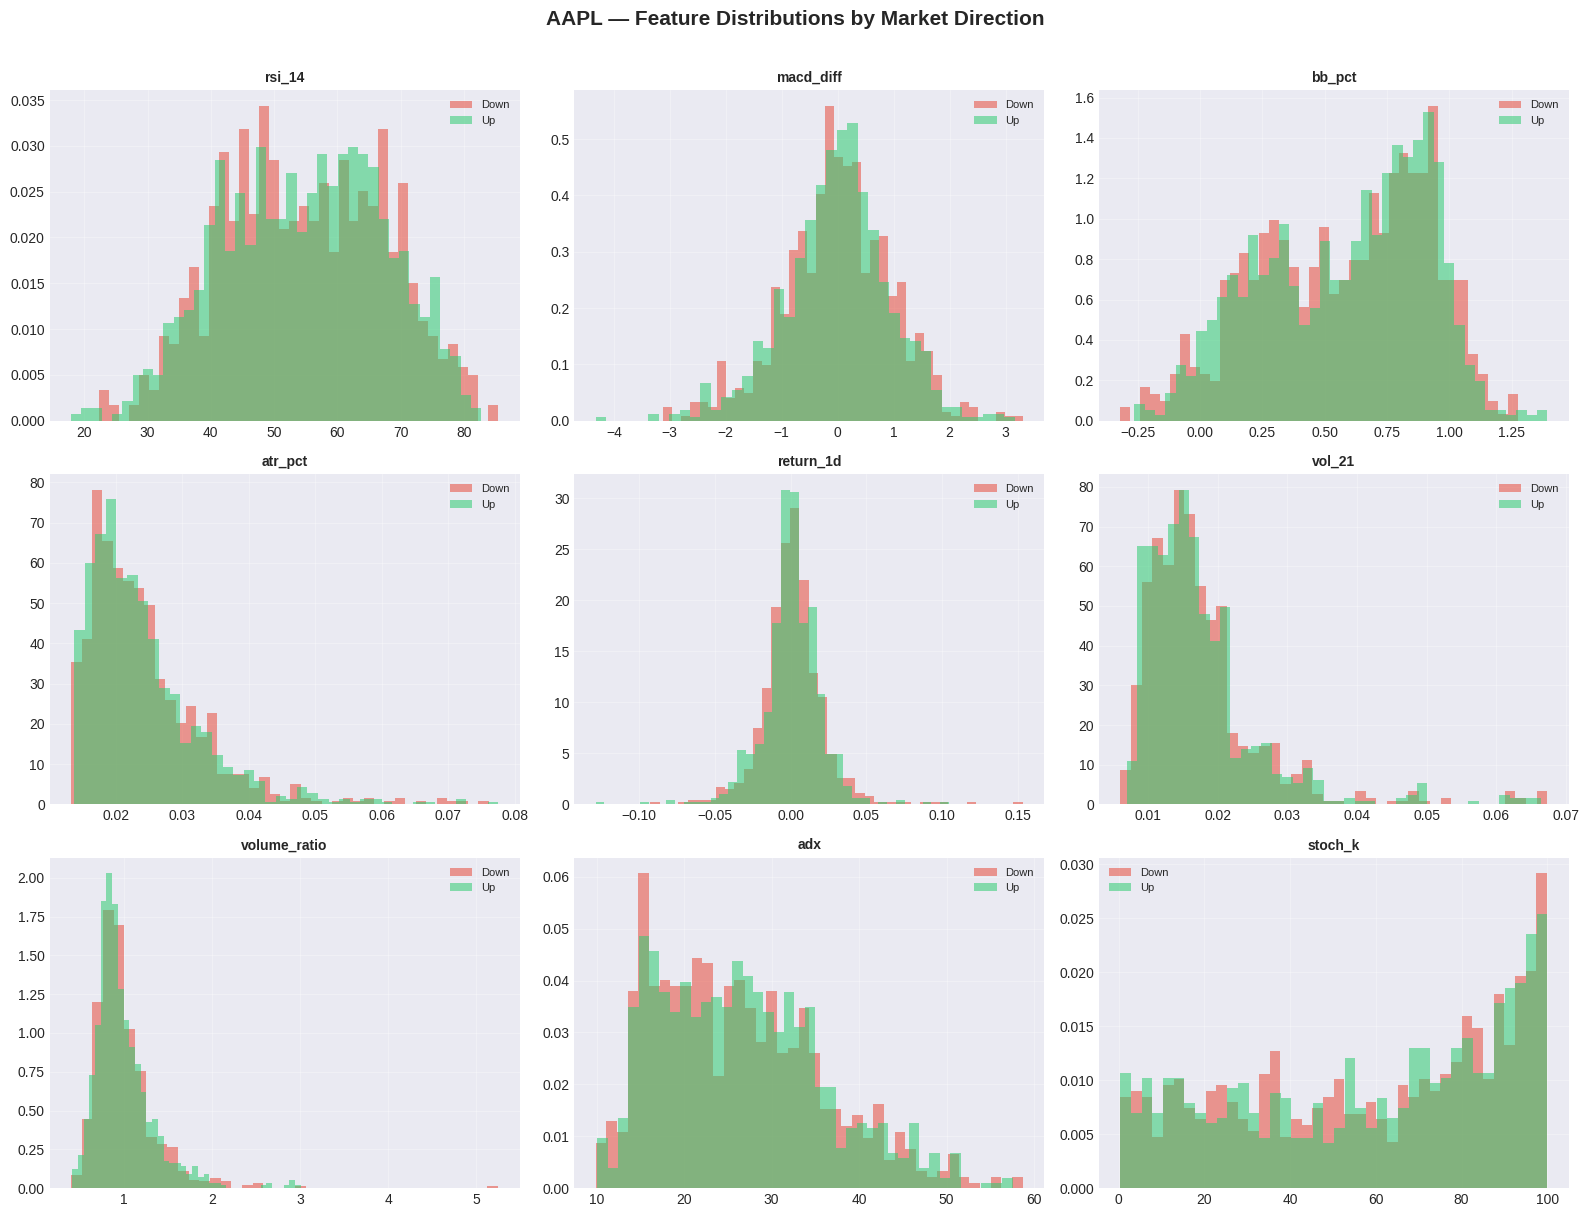

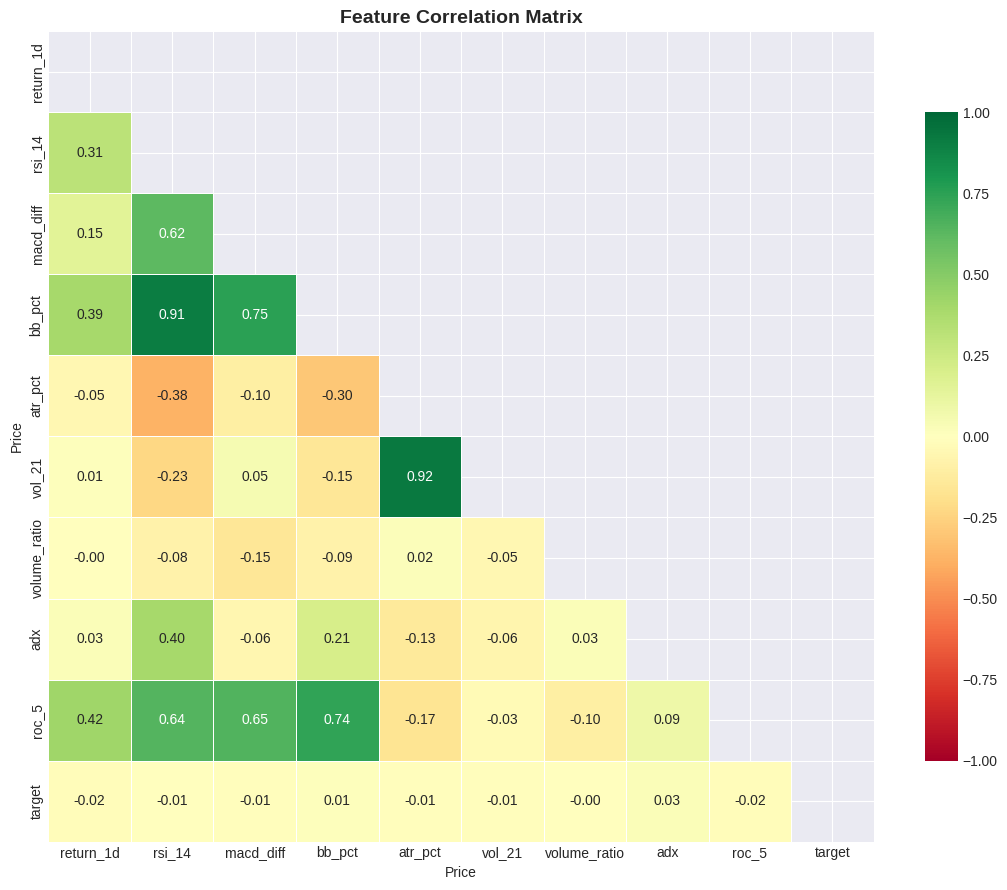

 EDA complete.


In [5]:
# ============================================================
#  CELL 5 — Exploratory Analysis of Features
# ============================================================
# "In God we trust; all others must bring data."
#                              — W. Edwards Deming
#
# A quick visual tour of our most important features before
# we hand them to the models. Understanding what the data
# looks like is half the battle.

fig, axes = plt.subplots(3, 3, figsize=(16, 12))
fig.suptitle(f'{TICKER} — Feature Distributions by Market Direction',
             fontsize=15, fontweight='bold', y=1.01)

key_features = ['rsi_14', 'macd_diff', 'bb_pct', 'atr_pct',
                'return_1d', 'vol_21', 'volume_ratio', 'adx', 'stoch_k']

for ax, feat in zip(axes.flat, key_features):
    for label, color in [(0, '#e74c3c'), (1, '#2ecc71')]:
        data = df[df['target'] == label][feat].dropna()
        ax.hist(data, bins=40, alpha=0.55, color=color,
                label='Down' if label == 0 else 'Up', density=True)
    ax.set_title(feat, fontsize=10, fontweight='bold')
    ax.legend(fontsize=8)
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('feature_distributions.png', dpi=150, bbox_inches='tight')
plt.show()

# Correlation heatmap of top features
top_features = ['return_1d', 'rsi_14', 'macd_diff', 'bb_pct',
                'atr_pct', 'vol_21', 'volume_ratio', 'adx', 'roc_5', 'target']

fig, ax = plt.subplots(figsize=(11, 9))
corr_matrix = df[top_features].corr()
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(corr_matrix, mask=mask, annot=True, fmt='.2f', cmap='RdYlGn',
            center=0, vmin=-1, vmax=1, ax=ax, linewidths=0.5, cbar_kws={'shrink': 0.8})
ax.set_title('Feature Correlation Matrix', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('correlation_heatmap.png', dpi=150, bbox_inches='tight')
plt.show()
print(" EDA complete.")

In [6]:
# ============================================================
#  CELL 6 — Train / Validation / Test Split (Time-Aware)
# ============================================================
# "In time series, randomly shuffling your data is not just
#  wrong — it's cheating. You're leaking the future."
#                    — A data science professor, sounding very stern
#
# We NEVER shuffle time-series data. The test set is always
# the most recent 15% — the part we've truly never seen.

X = df[FEATURE_COLS].values
y = df['target'].values
prices = df['Close'].values
next_prices = df['next_close'].values
dates = df.index

# Chronological split
n_total   = len(X)
n_test    = int(n_total * TEST_SPLIT)
n_train   = n_total - n_test

X_train_full = X[:n_train]
y_train_full = y[:n_train]
X_test       = X[n_train:]
y_test       = y[n_train:]
prices_test  = prices[n_train:]
next_prices_test = next_prices[n_train:]
dates_test   = dates[n_train:]

# Scale features (RobustScaler is more resistant to outliers than StandardScaler)
scaler   = RobustScaler()
X_train_scaled = scaler.fit_transform(X_train_full)
X_test_scaled  = scaler.transform(X_test)

print(f"   Data Split Summary")
print(f"   Training rows : {n_train:,}  ({dates[0].date()} → {dates[n_train-1].date()})")
print(f"   Test rows     : {n_test:,}   ({dates[n_train].date()} → {dates[-1].date()})")
print(f"   Features      : {X.shape[1]}")
print(f"   Train Up/Down : {y_train_full.sum()} / {(1-y_train_full).sum()}")
print(f"   Test  Up/Down : {y_test.sum()} / {(1-y_test).sum()}")

   Data Split Summary
   Training rows : 1,382  (2019-10-16 → 2025-04-15)
   Test rows     : 243   (2025-04-16 → 2026-04-06)
   Features      : 85
   Train Up/Down : 738 / 644
   Test  Up/Down : 130 / 113


   Training Random Forest with TimeSeriesSplit CV...
   Fold 1: F1=0.513  AUC=0.512
   Fold 2: F1=0.357  AUC=0.564
   Fold 3: F1=0.473  AUC=0.504
   Fold 4: F1=0.310  AUC=0.468
   Fold 5: F1=0.000  AUC=0.502

─────────────────────────────────────────────
  🌲 Random Forest — Test Set Results
─────────────────────────────────────────────
  F1-Score     : 0.3663
  ROC-AUC      : 0.5056
  Precision    : 0.5139
  Recall       : 0.2846
─────────────────────────────────────────────


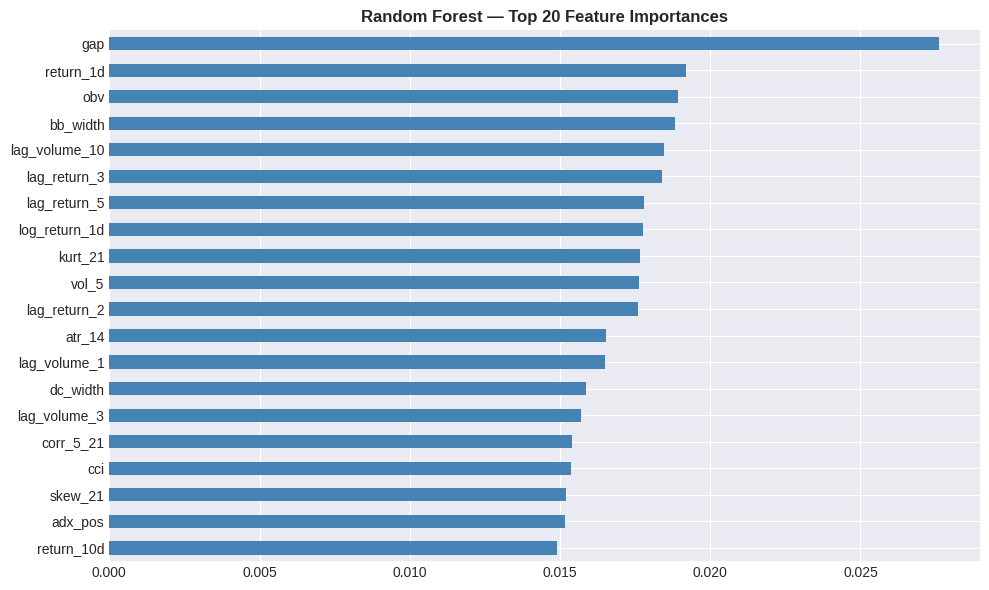

   Random Forest training complete.


In [7]:
# ============================================================
#  CELL 7 — Model 1: Random Forest with TimeSeriesSplit CV
# ============================================================
# "Random forests are like asking 1,000 friends for advice
#  and taking the majority vote. Surprisingly effective."
#                     — Leo Breiman would probably agree
#
# We use TimeSeriesSplit to respect temporal order during cross-validation.
# The best hyperparams are chosen from CV, then evaluated on the holdout test.

print("   Training Random Forest with TimeSeriesSplit CV...")

tscv = TimeSeriesSplit(n_splits=N_SPLITS)

rf_model = RandomForestClassifier(
    n_estimators    = 500,
    max_depth       = 8,
    min_samples_split = 20,
    min_samples_leaf  = 10,
    max_features    = 'sqrt',
    class_weight    = 'balanced',   # Handles class imbalance
    random_state    = RANDOM_STATE,
    n_jobs          = -1            # Use all CPU cores
)

# Time-series cross-validation
rf_cv_scores = {'f1': [], 'roc_auc': [], 'precision': [], 'recall': []}

for fold, (train_idx, val_idx) in enumerate(tscv.split(X_train_scaled)):
    Xf_tr, Xf_val = X_train_scaled[train_idx], X_train_scaled[val_idx]
    yf_tr, yf_val = y_train_full[train_idx],   y_train_full[val_idx]

    rf_model.fit(Xf_tr, yf_tr)
    y_pred_val = rf_model.predict(Xf_val)
    y_prob_val = rf_model.predict_proba(Xf_val)[:, 1]

    rf_cv_scores['f1'].append(f1_score(yf_val, y_pred_val))
    rf_cv_scores['roc_auc'].append(roc_auc_score(yf_val, y_prob_val))
    rf_cv_scores['precision'].append(precision_score(yf_val, y_pred_val))
    rf_cv_scores['recall'].append(recall_score(yf_val, y_pred_val))
    print(f"   Fold {fold+1}: F1={rf_cv_scores['f1'][-1]:.3f}  AUC={rf_cv_scores['roc_auc'][-1]:.3f}")

# Final fit on all training data
rf_model.fit(X_train_scaled, y_train_full)

# Evaluate on holdout test
rf_pred  = rf_model.predict(X_test_scaled)
rf_prob  = rf_model.predict_proba(X_test_scaled)[:, 1]

rf_results = {
    'F1-Score'  : f1_score(y_test, rf_pred),
    'ROC-AUC'   : roc_auc_score(y_test, rf_prob),
    'Precision' : precision_score(y_test, rf_pred),
    'Recall'    : recall_score(y_test, rf_pred),
}

print(f"\n{'─'*45}")
print(f"  🌲 Random Forest — Test Set Results")
print(f"{'─'*45}")
for k, v in rf_results.items():
    print(f"  {k:<12} : {v:.4f}")
print(f"{'─'*45}")

# Feature importance
feat_imp = pd.Series(rf_model.feature_importances_, index=FEATURE_COLS)\
             .sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(10, 6))
feat_imp.head(20).plot(kind='barh', ax=ax, color='steelblue')
ax.set_title('Random Forest — Top 20 Feature Importances', fontweight='bold')
ax.invert_yaxis()
plt.tight_layout()
plt.savefig('rf_feature_importance.png', dpi=150, bbox_inches='tight')
plt.show()
print("   Random Forest training complete.")

In [8]:
# ============================================================
#  CELL 8 — Model 2: XGBoost
# ============================================================
# "XGBoost is the algorithm that wins Kaggle competitions
#  and gets you promoted. In that order."
#             — The entire machine learning community, circa 2016–present
#
# XGBoost (eXtreme Gradient Boosting) builds trees sequentially,
# each one correcting the errors of the last — a very human-like
# approach to learning from mistakes.

print("   Training XGBoost with TimeSeriesSplit CV...")

xgb_model = XGBClassifier(
    n_estimators      = 600,
    max_depth         = 5,
    learning_rate     = 0.05,
    subsample         = 0.8,
    colsample_bytree  = 0.7,
    min_child_weight  = 10,
    reg_alpha         = 0.1,       # L1 regularisation
    reg_lambda        = 1.0,       # L2 regularisation
    scale_pos_weight  = (1 - y_train_full.mean()) / y_train_full.mean(),
    eval_metric       = 'logloss',
    use_label_encoder = False,
    random_state      = RANDOM_STATE,
    n_jobs            = -1,
    verbosity         = 0
)

xgb_cv_scores = {'f1': [], 'roc_auc': []}

for fold, (train_idx, val_idx) in enumerate(tscv.split(X_train_scaled)):
    Xf_tr, Xf_val = X_train_scaled[train_idx], X_train_scaled[val_idx]
    yf_tr, yf_val = y_train_full[train_idx],   y_train_full[val_idx]

    xgb_model.fit(Xf_tr, yf_tr,
                  eval_set=[(Xf_val, yf_val)],
                  verbose=False)
    y_pred_val = xgb_model.predict(Xf_val)
    y_prob_val = xgb_model.predict_proba(Xf_val)[:, 1]

    xgb_cv_scores['f1'].append(f1_score(yf_val, y_pred_val))
    xgb_cv_scores['roc_auc'].append(roc_auc_score(yf_val, y_prob_val))
    print(f"   Fold {fold+1}: F1={xgb_cv_scores['f1'][-1]:.3f}  AUC={xgb_cv_scores['roc_auc'][-1]:.3f}")

# Final fit
xgb_model.fit(X_train_scaled, y_train_full, verbose=False)

xgb_pred = xgb_model.predict(X_test_scaled)
xgb_prob = xgb_model.predict_proba(X_test_scaled)[:, 1]

xgb_results = {
    'F1-Score'  : f1_score(y_test, xgb_pred),
    'ROC-AUC'   : roc_auc_score(y_test, xgb_prob),
    'Precision' : precision_score(y_test, xgb_pred),
    'Recall'    : recall_score(y_test, xgb_pred),
}

print(f"\n{'─'*45}")
print(f"     XGBoost — Test Set Results")
print(f"{'─'*45}")
for k, v in xgb_results.items():
    print(f"  {k:<12} : {v:.4f}")
print(f"{'─'*45}")
print("   XGBoost training complete.")

   Training XGBoost with TimeSeriesSplit CV...
   Fold 1: F1=0.584  AUC=0.511
   Fold 2: F1=0.521  AUC=0.541
   Fold 3: F1=0.526  AUC=0.516
   Fold 4: F1=0.225  AUC=0.510
   Fold 5: F1=0.245  AUC=0.500

─────────────────────────────────────────────
     XGBoost — Test Set Results
─────────────────────────────────────────────
  F1-Score     : 0.5259
  ROC-AUC      : 0.4956
  Precision    : 0.5455
  Recall       : 0.5077
─────────────────────────────────────────────
   XGBoost training complete.


   Training sequences  : (1190, 60, 85)
   Validation sequences: (132, 60, 85)
   Test sequences      : (183, 60, 85)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ bidirectional (Bidirectional)   │ (None, 60, 256)        │       219,136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 60, 256)        │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 60, 256)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_1 (Bidirectional) │ (None, 128)            │       164,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         4,128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 389,185 (1.48 MB)

 Trainable params: 388,417 (1.48 MB)

 Non-trainable params: 768 (3.00 KB)


🧠 Training BiLSTM...
Epoch 1/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 9s 64ms/step - accuracy: 0.5084 - auc: 0.5196 - loss: 0.8332 - val_accuracy: 0.5227 - val_auc: 0.5740 - val_loss: 0.6901 - learning_rate: 0.0010
Epoch 2/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - accuracy: 0.5387 - auc: 0.5490 - loss: 0.7590 - val_accuracy: 0.5227 - val_auc: 0.5232 - val_loss: 0.7017 - learning_rate: 0.0010
Epoch 3/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - accuracy: 0.5420 - auc: 0.5640 - loss: 0.7327 - val_accuracy: 0.5227 - val_auc: 0.4997 - val_loss: 0.7012 - learning_rate: 0.0010
Epoch 4/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - accuracy: 0.5555 - auc: 0.5784 - loss: 0.7224 - val_accuracy: 0.5227 - val_auc: 0.4986 - val_loss: 0.6965 - learning_rate: 0.0010
Epoch 5/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 1s 23ms/step - accuracy: 0.5782 - auc: 0.6010 - loss: 0.7038 - val_accuracy: 0.5227 - val_auc: 0.4464 - val_loss: 0.7083 - learning_rate: 0.0010
Epoch 6/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - accu

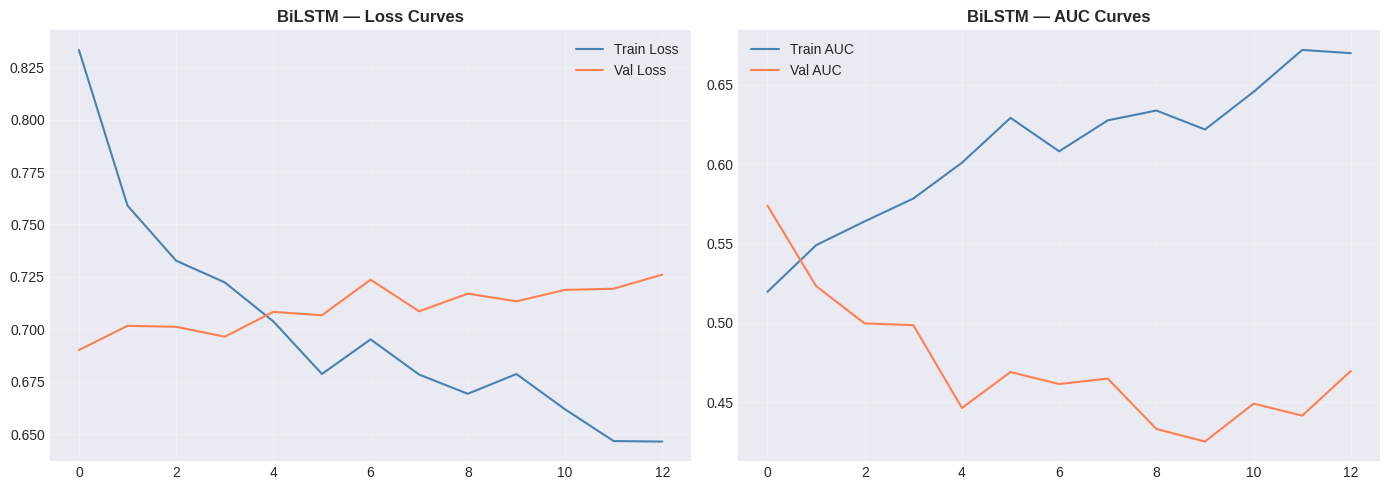

   BiLSTM training complete.


In [9]:
# ============================================================
#  CELL 9 — Model 3: Bidirectional LSTM (BiLSTM)
# ============================================================
# "A BiLSTM is like a detective who reads a story forwards
#  and backwards before drawing conclusions."
#                    — Someone explaining neural networks at 2 AM
#
# Unlike tree models that treat each row independently,
# the BiLSTM sees sequences of SEQUENCE_LEN days at a time.
# This lets it capture temporal patterns that tabular models miss.
#
# Architecture:
#   Input(60, n_features)
#     → BiLSTM(128) → BatchNorm → Dropout
#     → BiLSTM(64)  → BatchNorm → Dropout
#     → Dense(32, relu)
#     → Dense(1, sigmoid)

def build_sequences(X_arr, y_arr, seq_len):
    """Convert a 2D feature array into 3D sequences for LSTM."""
    Xs, ys = [], []
    for i in range(seq_len, len(X_arr)):
        Xs.append(X_arr[i - seq_len : i])
        ys.append(y_arr[i])
    return np.array(Xs), np.array(ys)

# Build sequences
X_seq_train, y_seq_train = build_sequences(X_train_scaled, y_train_full, SEQUENCE_LEN)
X_seq_test,  y_seq_test  = build_sequences(X_test_scaled,  y_test,       SEQUENCE_LEN)

# Validation split from training sequences
n_val = int(len(X_seq_train) * VAL_SPLIT)
X_seq_val   = X_seq_train[-n_val:]
y_seq_val   = y_seq_train[-n_val:]
X_seq_train2 = X_seq_train[:-n_val]
y_seq_train2 = y_seq_train[:-n_val]

n_features = X_seq_train.shape[2]
print(f"   Training sequences  : {X_seq_train2.shape}")
print(f"   Validation sequences: {X_seq_val.shape}")
print(f"   Test sequences      : {X_seq_test.shape}")

# ── BiLSTM Architecture ────────────────────────────────────
def build_bilstm(seq_len, n_features, lstm_units, dropout_rate, lr):
    """Build and compile the BiLSTM model."""
    model = Sequential([
        Input(shape=(seq_len, n_features)),

        # First BiLSTM block
        Bidirectional(LSTM(lstm_units, return_sequences=True)),
        BatchNormalization(),
        Dropout(dropout_rate),

        # Second BiLSTM block (half the units)
        Bidirectional(LSTM(lstm_units // 2, return_sequences=False)),
        BatchNormalization(),
        Dropout(dropout_rate),

        # Fully connected head
        Dense(32, activation='relu'),
        Dropout(dropout_rate / 2),
        Dense(1, activation='sigmoid')  # Binary output: probability of going UP
    ])

    model.compile(
        optimizer = Adam(learning_rate=lr),
        loss      = 'binary_crossentropy',
        metrics   = ['accuracy', tf.keras.metrics.AUC(name='auc')]
    )
    return model

bilstm = build_bilstm(SEQUENCE_LEN, n_features, LSTM_UNITS, DROPOUT_RATE, LEARNING_RATE)
bilstm.summary()

# Callbacks
callbacks = [
    EarlyStopping(monitor='val_auc', patience=12, restore_best_weights=True, mode='max',
                  verbose=1),
    ReduceLROnPlateau(monitor='val_loss', patience=6, factor=0.5, min_lr=1e-6, verbose=1)
]

# Train
print("\n🧠 Training BiLSTM...")
history = bilstm.fit(
    X_seq_train2, y_seq_train2,
    validation_data = (X_seq_val, y_seq_val),
    epochs          = MAX_EPOCHS,
    batch_size      = BATCH_SIZE,
    callbacks       = callbacks,
    verbose         = 1
)

# Evaluate
bilstm_prob_seq = bilstm.predict(X_seq_test).flatten()
bilstm_pred_seq = (bilstm_prob_seq > 0.5).astype(int)

# Align test labels with sequences
y_test_seq = y_test[SEQUENCE_LEN:]

bilstm_results = {
    'F1-Score'  : f1_score(y_test_seq, bilstm_pred_seq),
    'ROC-AUC'   : roc_auc_score(y_test_seq, bilstm_prob_seq),
    'Precision' : precision_score(y_test_seq, bilstm_pred_seq),
    'Recall'    : recall_score(y_test_seq, bilstm_pred_seq),
}

print(f"\n{'─'*45}")
print(f"   BiLSTM — Test Set Results")
print(f"{'─'*45}")
for k, v in bilstm_results.items():
    print(f"  {k:<12} : {v:.4f}")
print(f"{'─'*45}")

# Training history plot
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(history.history['loss'],     label='Train Loss', color='steelblue')
axes[0].plot(history.history['val_loss'], label='Val Loss',   color='coral')
axes[0].set_title('BiLSTM — Loss Curves', fontweight='bold')
axes[0].legend(); axes[0].grid(True, alpha=0.3)

axes[1].plot(history.history['auc'],     label='Train AUC', color='steelblue')
axes[1].plot(history.history['val_auc'], label='Val AUC',   color='coral')
axes[1].set_title('BiLSTM — AUC Curves', fontweight='bold')
axes[1].legend(); axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('bilstm_training_history.png', dpi=150, bbox_inches='tight')
plt.show()
print("   BiLSTM training complete.")


     HEAD-TO-HEAD MODEL COMPARISON
               F1-Score  ROC-AUC  Precision  Recall
Model                                              
Random Forest    0.2595   0.5063     0.4722  0.1789
XGBoost          0.5348   0.4914     0.5435  0.5263
BiLSTM           0.6716   0.4761     0.5202  0.9474

   Best model (by F1-Score): BiLSTM


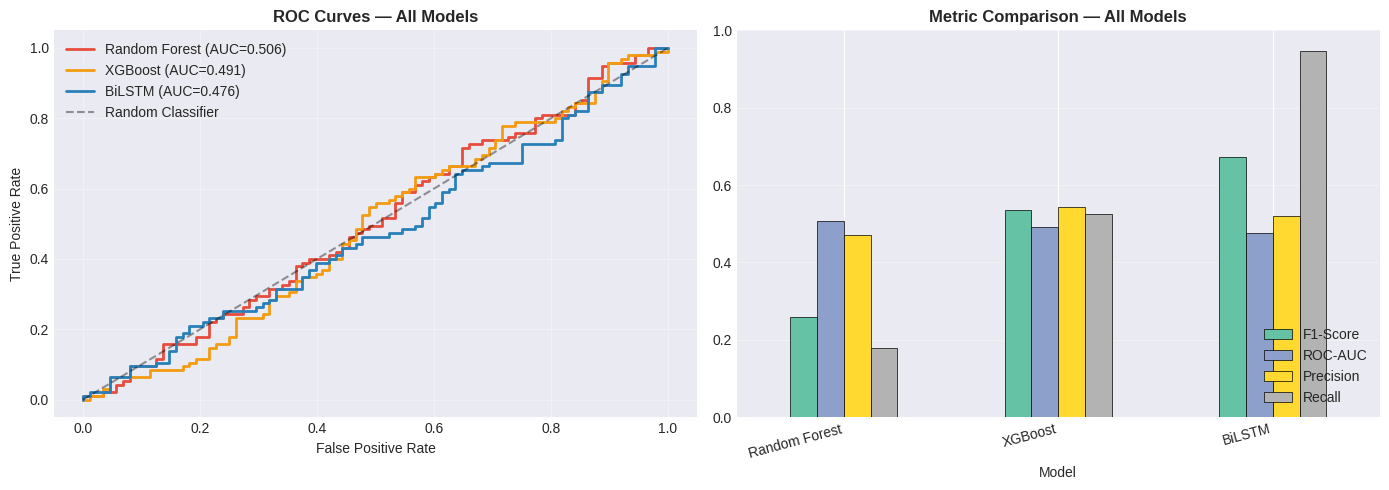

In [10]:
# ============================================================
#  CELL 10 — Model Comparison & ROC Curves
# ============================================================
# "All models are wrong, but some are useful."
#                              — George E. P. Box
#
# Head-to-head comparison of all three models on the test set.
# We pick the winner and carry it forward to backtesting.

# Align test data sizes for fair comparison
# (BiLSTM needs SEQUENCE_LEN warm-up rows, so we trim the others to match)
trim = SEQUENCE_LEN
rf_pred_trim  = rf_pred[trim:]
rf_prob_trim  = rf_prob[trim:]
xgb_pred_trim = xgb_pred[trim:]
xgb_prob_trim = xgb_prob[trim:]
y_test_trim   = y_test[trim:]

comparison = pd.DataFrame({
    'Model'     : ['Random Forest', 'XGBoost', 'BiLSTM'],
    'F1-Score'  : [
        f1_score(y_test_trim, rf_pred_trim),
        f1_score(y_test_trim, xgb_pred_trim),
        f1_score(y_test_seq,  bilstm_pred_seq)
    ],
    'ROC-AUC'   : [
        roc_auc_score(y_test_trim, rf_prob_trim),
        roc_auc_score(y_test_trim, xgb_prob_trim),
        roc_auc_score(y_test_seq,  bilstm_prob_seq)
    ],
    'Precision' : [
        precision_score(y_test_trim, rf_pred_trim),
        precision_score(y_test_trim, xgb_pred_trim),
        precision_score(y_test_seq,  bilstm_pred_seq)
    ],
    'Recall'    : [
        recall_score(y_test_trim, rf_pred_trim),
        recall_score(y_test_trim, xgb_pred_trim),
        recall_score(y_test_seq,  bilstm_pred_seq)
    ],
})
comparison.set_index('Model', inplace=True)

print("\n" + "="*55)
print("     HEAD-TO-HEAD MODEL COMPARISON")
print("="*55)
print(comparison.to_string())
print("="*55)

BEST_MODEL = comparison['F1-Score'].idxmax()
print(f"\n   Best model (by F1-Score): {BEST_MODEL}")

# ── ROC Curves ─────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# ROC Curves
for name, y_true, y_prob, color in [
    ('Random Forest', y_test_trim, rf_prob_trim,  '#e74c3c'),
    ('XGBoost',       y_test_trim, xgb_prob_trim, '#f39c12'),
    ('BiLSTM',        y_test_seq,  bilstm_prob_seq,'#2980b9'),
]:
    fpr, tpr, _ = roc_curve(y_true, y_prob)
    auc_val = roc_auc_score(y_true, y_prob)
    axes[0].plot(fpr, tpr, label=f'{name} (AUC={auc_val:.3f})', color=color, lw=2)

axes[0].plot([0, 1], [0, 1], 'k--', alpha=0.4, label='Random Classifier')
axes[0].set_title('ROC Curves — All Models', fontweight='bold')
axes[0].set_xlabel('False Positive Rate')
axes[0].set_ylabel('True Positive Rate')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Metric bar chart
comparison.plot(kind='bar', ax=axes[1], colormap='Set2', edgecolor='black', linewidth=0.5)
axes[1].set_title('Metric Comparison — All Models', fontweight='bold')
axes[1].set_xticklabels(comparison.index, rotation=15, ha='right')
axes[1].legend(loc='lower right')
axes[1].set_ylim(0, 1)
axes[1].grid(True, alpha=0.3, axis='y')

plt.tight_layout()
plt.savefig('model_comparison.png', dpi=150, bbox_inches='tight')
plt.show()


     BACKTEST RESULTS
                     Total Return Annual Return Annual Volatility Sharpe Ratio Max Drawdown Calmar Ratio
Name                                                                                                    
Buy & Hold                 21.60%        30.90%            22.86%        1.117      -13.80%        2.239
ML Strategy (BiLSTM)       22.04%        31.55%            22.74%        1.143      -13.80%        2.287

  Win Rate (Directional Accuracy) : 51.91%


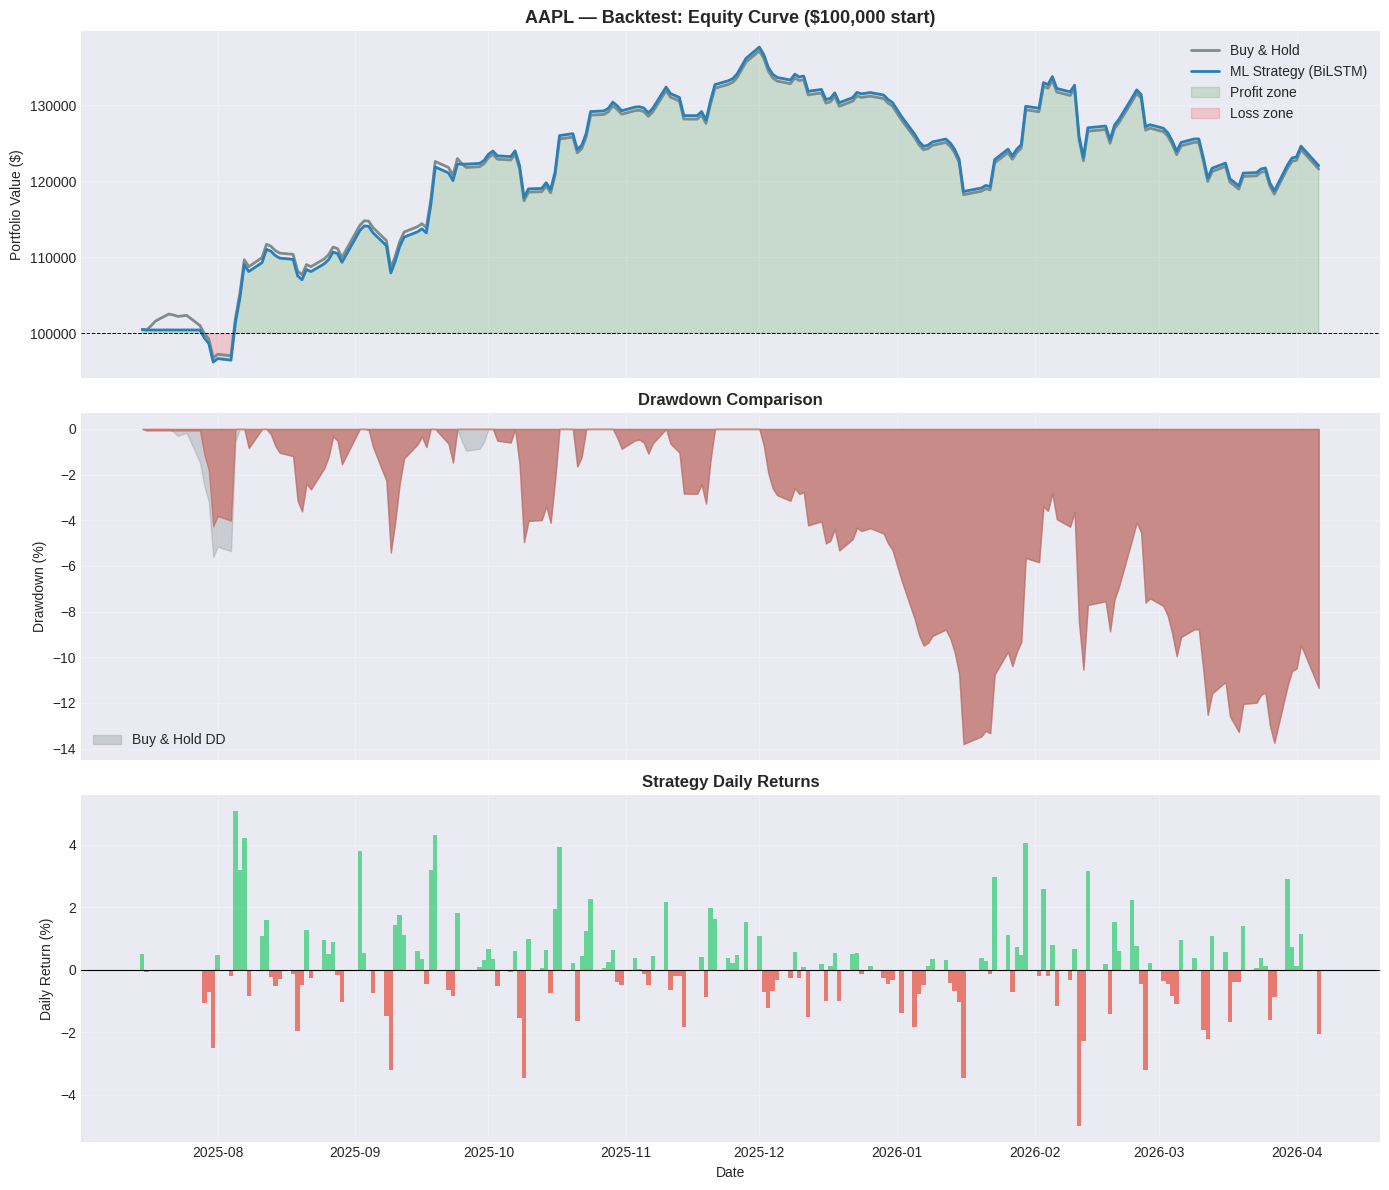

  Backtesting complete.


In [11]:
# ============================================================
#  CELL 11 — Backtesting Framework
# ============================================================
# "It doesn't matter how good your model is if your strategy
#  would have gone bankrupt in 2008."
#                     — Every quantitative finance professor ever
#
# We backtest the best-performing model against a simple
# Buy-and-Hold benchmark. Key metrics:
#   • Cumulative Return
#   • Sharpe Ratio   (return per unit of risk)
#   • Max Drawdown   (worst peak-to-trough loss)
#   • Win Rate       (% of days we were right)
#   • Calmar Ratio   (return / max drawdown)

def compute_backtest_metrics(returns, name='Strategy', rf_rate=0.04):
    """
    Compute full backtest metrics from a series of daily returns.
    rf_rate = annual risk-free rate (e.g. 0.04 for 4%).
    """
    daily_rf   = rf_rate / TRADING_DAYS
    excess_ret = returns - daily_rf

    cumulative  = (1 + returns).cumprod()
    total_ret   = cumulative.iloc[-1] - 1
    annual_ret  = (1 + total_ret) ** (TRADING_DAYS / len(returns)) - 1
    annual_vol  = returns.std() * np.sqrt(TRADING_DAYS)
    sharpe      = (excess_ret.mean() / excess_ret.std()) * np.sqrt(TRADING_DAYS)

    # Maximum Drawdown
    roll_max    = cumulative.cummax()
    drawdown    = (cumulative - roll_max) / roll_max
    max_dd      = drawdown.min()

    calmar      = annual_ret / abs(max_dd) if max_dd != 0 else 0

    return {
        'Name'             : name,
        'Total Return'     : f"{total_ret*100:.2f}%",
        'Annual Return'    : f"{annual_ret*100:.2f}%",
        'Annual Volatility': f"{annual_vol*100:.2f}%",
        'Sharpe Ratio'     : f"{sharpe:.3f}",
        'Max Drawdown'     : f"{max_dd*100:.2f}%",
        'Calmar Ratio'     : f"{calmar:.3f}",
        '_cumulative'      : cumulative,
        '_drawdown'        : drawdown,
    }

# ── Build trading signals ─────────────────────────────────
# Strategy: go LONG (hold) when model predicts UP, else CASH (0 return).
# We use the BiLSTM predictions on the aligned test slice.

test_prices_seq   = prices_test[SEQUENCE_LEN:]     # Aligned with BiLSTM output
test_nextpx_seq   = next_prices_test[SEQUENCE_LEN:]
test_dates_seq    = dates_test[SEQUENCE_LEN:]

# Daily returns from the actual market
market_returns    = pd.Series(
    (test_nextpx_seq - test_prices_seq) / test_prices_seq,
    index=test_dates_seq
).dropna()

# Select the best model's predictions for backtesting
if BEST_MODEL == 'BiLSTM':
    best_signals = bilstm_pred_seq[:len(market_returns)]
elif BEST_MODEL == 'XGBoost':
    best_signals = xgb_pred_trim[:len(market_returns)]
else:
    best_signals = rf_pred_trim[:len(market_returns)]

# Strategy returns: only capture the return on days we predict UP
strategy_returns  = pd.Series(
    market_returns.values * best_signals,
    index=market_returns.index
)

# Compute metrics
bnh  = compute_backtest_metrics(market_returns,   name='Buy & Hold')
strat = compute_backtest_metrics(strategy_returns, name=f'ML Strategy ({BEST_MODEL})')

print("\n" + "="*55)
print("     BACKTEST RESULTS")
print("="*55)
metrics_df = pd.DataFrame([bnh, strat]).set_index('Name')
disp_cols = ['Total Return', 'Annual Return', 'Annual Volatility',
             'Sharpe Ratio', 'Max Drawdown', 'Calmar Ratio']
print(metrics_df[disp_cols].to_string())
print("="*55)

win_rate = (best_signals == y_test_trim[:len(best_signals)]).mean()
print(f"\n  Win Rate (Directional Accuracy) : {win_rate*100:.2f}%")

# ── Backtest Visualisation ───────────────────────────────
fig, axes = plt.subplots(3, 1, figsize=(14, 12), sharex=True)

# 1. Cumulative Returns
equity_bnh   = bnh['_cumulative']  * INITIAL_CAPITAL
equity_strat = strat['_cumulative'] * INITIAL_CAPITAL

axes[0].plot(equity_bnh.index,   equity_bnh,   color='#7f8c8d', lw=2, label='Buy & Hold')
axes[0].plot(equity_strat.index, equity_strat, color='#2980b9', lw=2, label=f'ML Strategy ({BEST_MODEL})')
axes[0].fill_between(equity_strat.index, INITIAL_CAPITAL,
                     equity_strat, where=equity_strat >= INITIAL_CAPITAL,
                     alpha=0.15, color='green', label='Profit zone')
axes[0].fill_between(equity_strat.index, INITIAL_CAPITAL,
                     equity_strat, where=equity_strat < INITIAL_CAPITAL,
                     alpha=0.15, color='red', label='Loss zone')
axes[0].axhline(INITIAL_CAPITAL, color='black', linewidth=0.7, linestyle='--')
axes[0].set_title(f'{TICKER} — Backtest: Equity Curve (${INITIAL_CAPITAL:,} start)',
                  fontweight='bold', fontsize=13)
axes[0].set_ylabel('Portfolio Value ($)')
axes[0].legend()

# 2. Drawdown
axes[1].fill_between(strat['_drawdown'].index,
                     strat['_drawdown'] * 100, 0, alpha=0.6, color='#e74c3c')
axes[1].fill_between(bnh['_drawdown'].index,
                     bnh['_drawdown'] * 100,  0, alpha=0.3, color='#7f8c8d', label='Buy & Hold DD')
axes[1].set_ylabel('Drawdown (%)')
axes[1].set_title('Drawdown Comparison', fontweight='bold')
axes[1].legend()

# 3. Daily strategy returns
axes[2].bar(strategy_returns.index,
            strategy_returns * 100,
            color=np.where(strategy_returns >= 0, '#2ecc71', '#e74c3c'),
            alpha=0.7, width=1)
axes[2].axhline(0, color='black', linewidth=0.8)
axes[2].set_ylabel('Daily Return (%)')
axes[2].set_title('Strategy Daily Returns', fontweight='bold')
axes[2].set_xlabel('Date')

for ax in axes:
    ax.grid(True, alpha=0.25)

plt.tight_layout()
plt.savefig('backtest_results.png', dpi=150, bbox_inches='tight')
plt.show()
print("  Backtesting complete.")

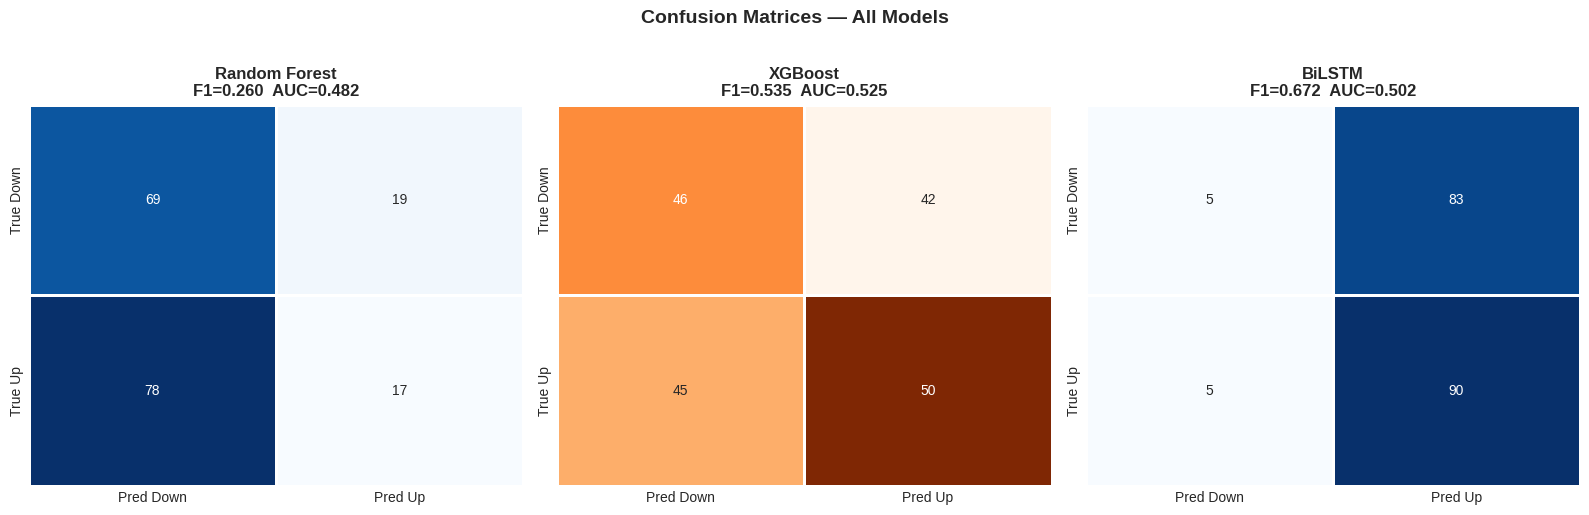

In [12]:
# ============================================================
#  CELL 12 — Confusion Matrices
# ============================================================
# "A confusion matrix is just a scoreboard.
#  Four numbers that tell you everything about how you lost."
#                              — A recovering overconfident ML engineer

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

model_names = ['Random Forest', 'XGBoost', 'BiLSTM']
preds_list  = [rf_pred_trim, xgb_pred_trim, bilstm_pred_seq]
y_list      = [y_test_trim, y_test_trim, y_test_seq]
colors      = ['Blues', 'Oranges', 'Blues']

for ax, name, pred, ytrue, cmap in zip(axes, model_names, preds_list, y_list, colors):
    cm = confusion_matrix(ytrue, pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap=cmap, ax=ax,
                xticklabels=['Pred Down', 'Pred Up'],
                yticklabels=['True Down', 'True Up'],
                cbar=False, linewidths=1)
    ax.set_title(f'{name}\nF1={f1_score(ytrue, pred):.3f}  AUC={roc_auc_score(ytrue, pred):.3f}',
                 fontweight='bold')

plt.suptitle('Confusion Matrices — All Models', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('confusion_matrices.png', dpi=150, bbox_inches='tight')
plt.show()

   Computing SHAP values for XGBoost...


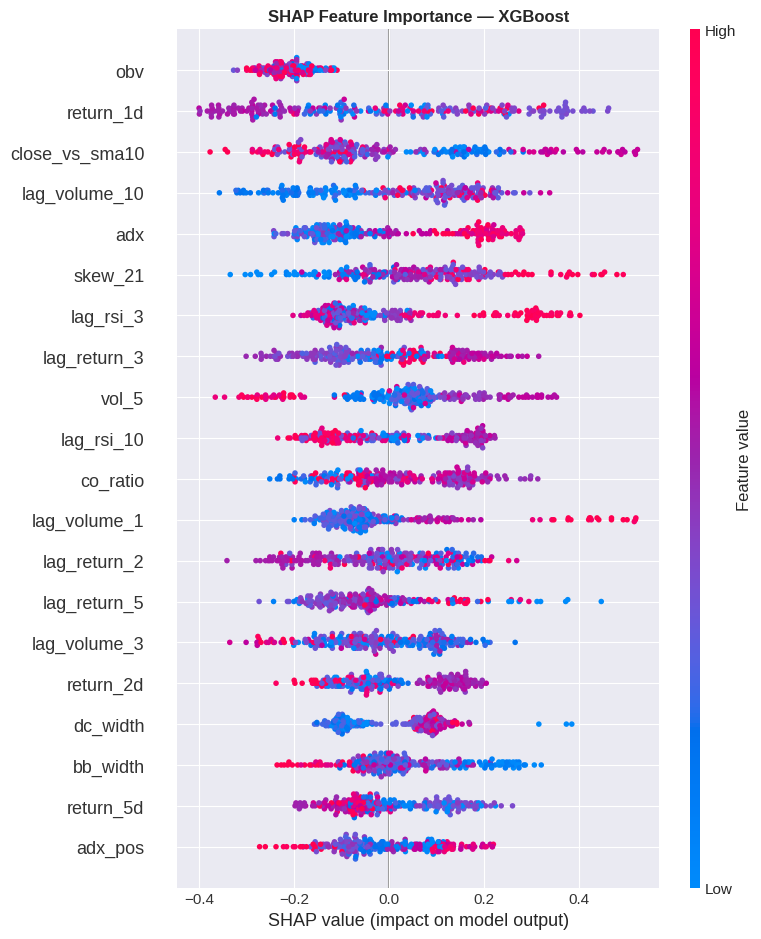

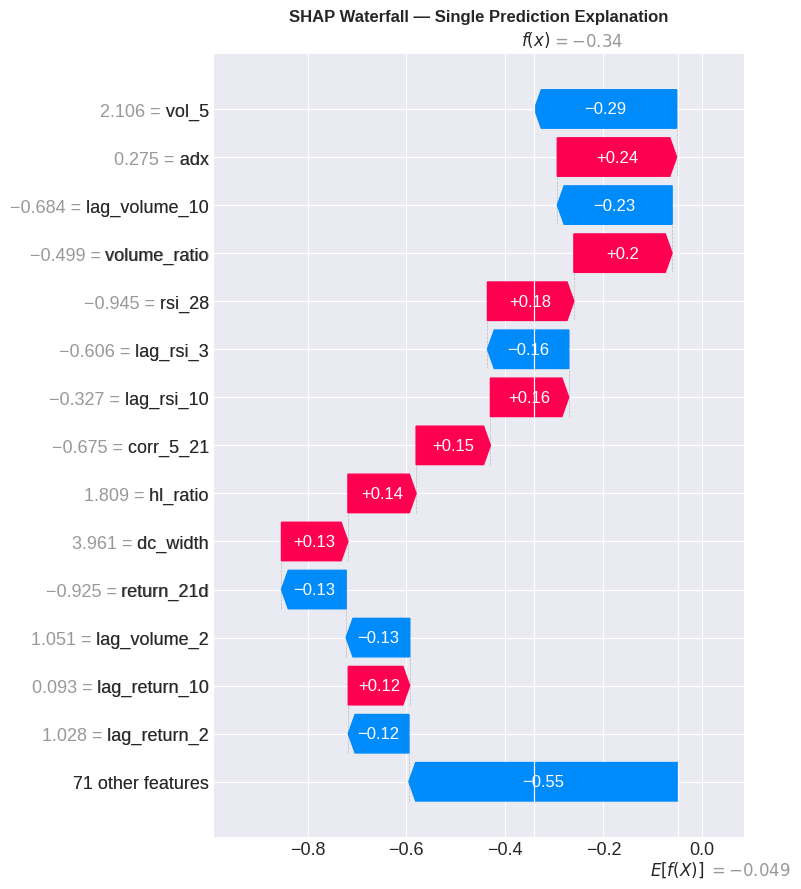

   SHAP explainability complete.


In [13]:
# ============================================================
#  CELL 13 — SHAP Explainability (XGBoost)
# ============================================================
# "Explainability is not a luxury — in financial markets,
#  it's the difference between a model you trust and one
#  you just hope works."
#                    — Broadly, the entire SHAP paper (Lundberg & Lee, 2017)
#
# SHAP values tell us HOW MUCH each feature contributed
# to a specific prediction — not just globally important,
# but important for this particular trading day.

print("   Computing SHAP values for XGBoost...")

explainer    = shap.TreeExplainer(xgb_model)
shap_values  = explainer.shap_values(X_test_scaled[:300])  # Sample for speed

# Summary (beeswarm) plot
plt.figure(figsize=(10, 8))
shap.summary_plot(shap_values, X_test_scaled[:300],
                  feature_names=FEATURE_COLS,
                  max_display=20, show=False)
plt.title('SHAP Feature Importance — XGBoost', fontweight='bold')
plt.tight_layout()
plt.savefig('shap_summary.png', dpi=150, bbox_inches='tight')
plt.show()

# Waterfall plot for a single prediction
shap_exp = shap.Explanation(
    values     = shap_values[0],
    base_values= explainer.expected_value,
    data       = X_test_scaled[0],
    feature_names = FEATURE_COLS
)
plt.figure(figsize=(10, 6))
shap.waterfall_plot(shap_exp, max_display=15, show=False)
plt.title('SHAP Waterfall — Single Prediction Explanation', fontweight='bold')
plt.tight_layout()
plt.savefig('shap_waterfall.png', dpi=150, bbox_inches='tight')
plt.show()
print("   SHAP explainability complete.")

In [14]:
import pandas as pd
from pandas.tseries.offsets import BusinessDay

# ============================================================
#  CELL 14 —    Next-Day Prediction
# ============================================================
# "Prediction is very difficult, especially if it's about the future."
#                                     — Niels Bohr
#
# We take the LATEST row(s) of data and ask each model:
# What direction does tomorrow look like?
# Confidence = probability from the model's output.
# Estimated Price = today's close ± expected magnitude.

latest_close  = float(raw_df['Close'].iloc[-1])
latest_date   = raw_df.index[-1].date()
next_date_est = raw_df.index[-1] + BusinessDay(1)  # Next business day

# Latest scaled features
latest_features = scaler.transform(df[FEATURE_COLS].iloc[[-1]])

# BiLSTM needs a sequence
latest_seq = X_train_scaled[-SEQUENCE_LEN:].reshape(1, SEQUENCE_LEN, n_features)
bilstm_conf_latest  = float(bilstm.predict(latest_seq)[0][0])
bilstm_dir_latest   = "   UP" if bilstm_conf_latest > 0.5 else "   DOWN"

# RF & XGBoost
rf_conf_latest   = float(rf_model.predict_proba(latest_features)[0][1])
rf_dir_latest    = " UP" if rf_conf_latest > 0.5 else " DOWN"
xgb_conf_latest  = float(xgb_model.predict_proba(latest_features)[0][1])
xgb_dir_latest   = " UP" if xgb_conf_latest > 0.5 else " DOWN"

# Ensemble: average all three probabilities
ensemble_conf = (rf_conf_latest + xgb_conf_latest + bilstm_conf_latest) / 3
ensemble_dir  = " UP" if ensemble_conf > 0.5 else " DOWN"

# Estimated price using average historical 1-day return magnitude
avg_abs_return = df['return_1d'].abs().rolling(21).mean().iloc[-1]
direction_mult = 1 if ensemble_conf > 0.5 else -1
estimated_price = latest_close * (1 + direction_mult * avg_abs_return)

print(f"\n{'='*58}")
print(f"   NEXT-DAY PREDICTION REPORT")
print(f"{'='*58}")
print(f"  Stock          : {TICKER}")
print(f"  Last Close     : ${latest_close:.2f}  ({latest_date})")
print(f"  Next Trading   : {next_date_est.date()}")
print(f"{'─'*58}")
print(f"  Model              Direction    Confidence")
print(f"{'─'*58}")
print(f"  Random Forest      {rf_dir_latest:<12} {rf_conf_latest*100:.1f}%")
print(f"  XGBoost            {xgb_dir_latest:<12} {xgb_conf_latest*100:.1f}%")
print(f"  BiLSTM             {bilstm_dir_latest:<12} {bilstm_conf_latest*100:.1f}%")
print(f"{'─'*58}")
print(f"   ENSEMBLE        {ensemble_dir:<12} {ensemble_conf*100:.1f}%")
print(f"{'─'*58}")
print(f"   Estimated Next Close : ${estimated_price:.2f}")
print(f"   Expected Move        : {direction_mult * avg_abs_return * 100:.2f}%")
print(f"{'='*58}")
print()
print("⚠️  DISCLAIMER: This is for educational purposes only.")
print("   Past model performance does NOT guarantee future returns.")
print("   Never make financial decisions based solely on ML predictions.")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step

   NEXT-DAY PREDICTION REPORT
  Stock          : AAPL
  Last Close     : $253.50  (2026-04-07)
  Next Trading   : 2026-04-08
──────────────────────────────────────────────────────────
  Model              Direction    Confidence
──────────────────────────────────────────────────────────
  Random Forest       DOWN        42.3%
  XGBoost             UP          72.4%
  BiLSTM                UP        58.1%
──────────────────────────────────────────────────────────
   ENSEMBLE         UP          57.6%
──────────────────────────────────────────────────────────
   Estimated Next Close : $255.91
   Expected Move        : 0.95%

⚠️  DISCLAIMER: This is for educational purposes only.
   Past model performance does NOT guarantee future returns.
   Never make financial decisions based solely on ML predictions.


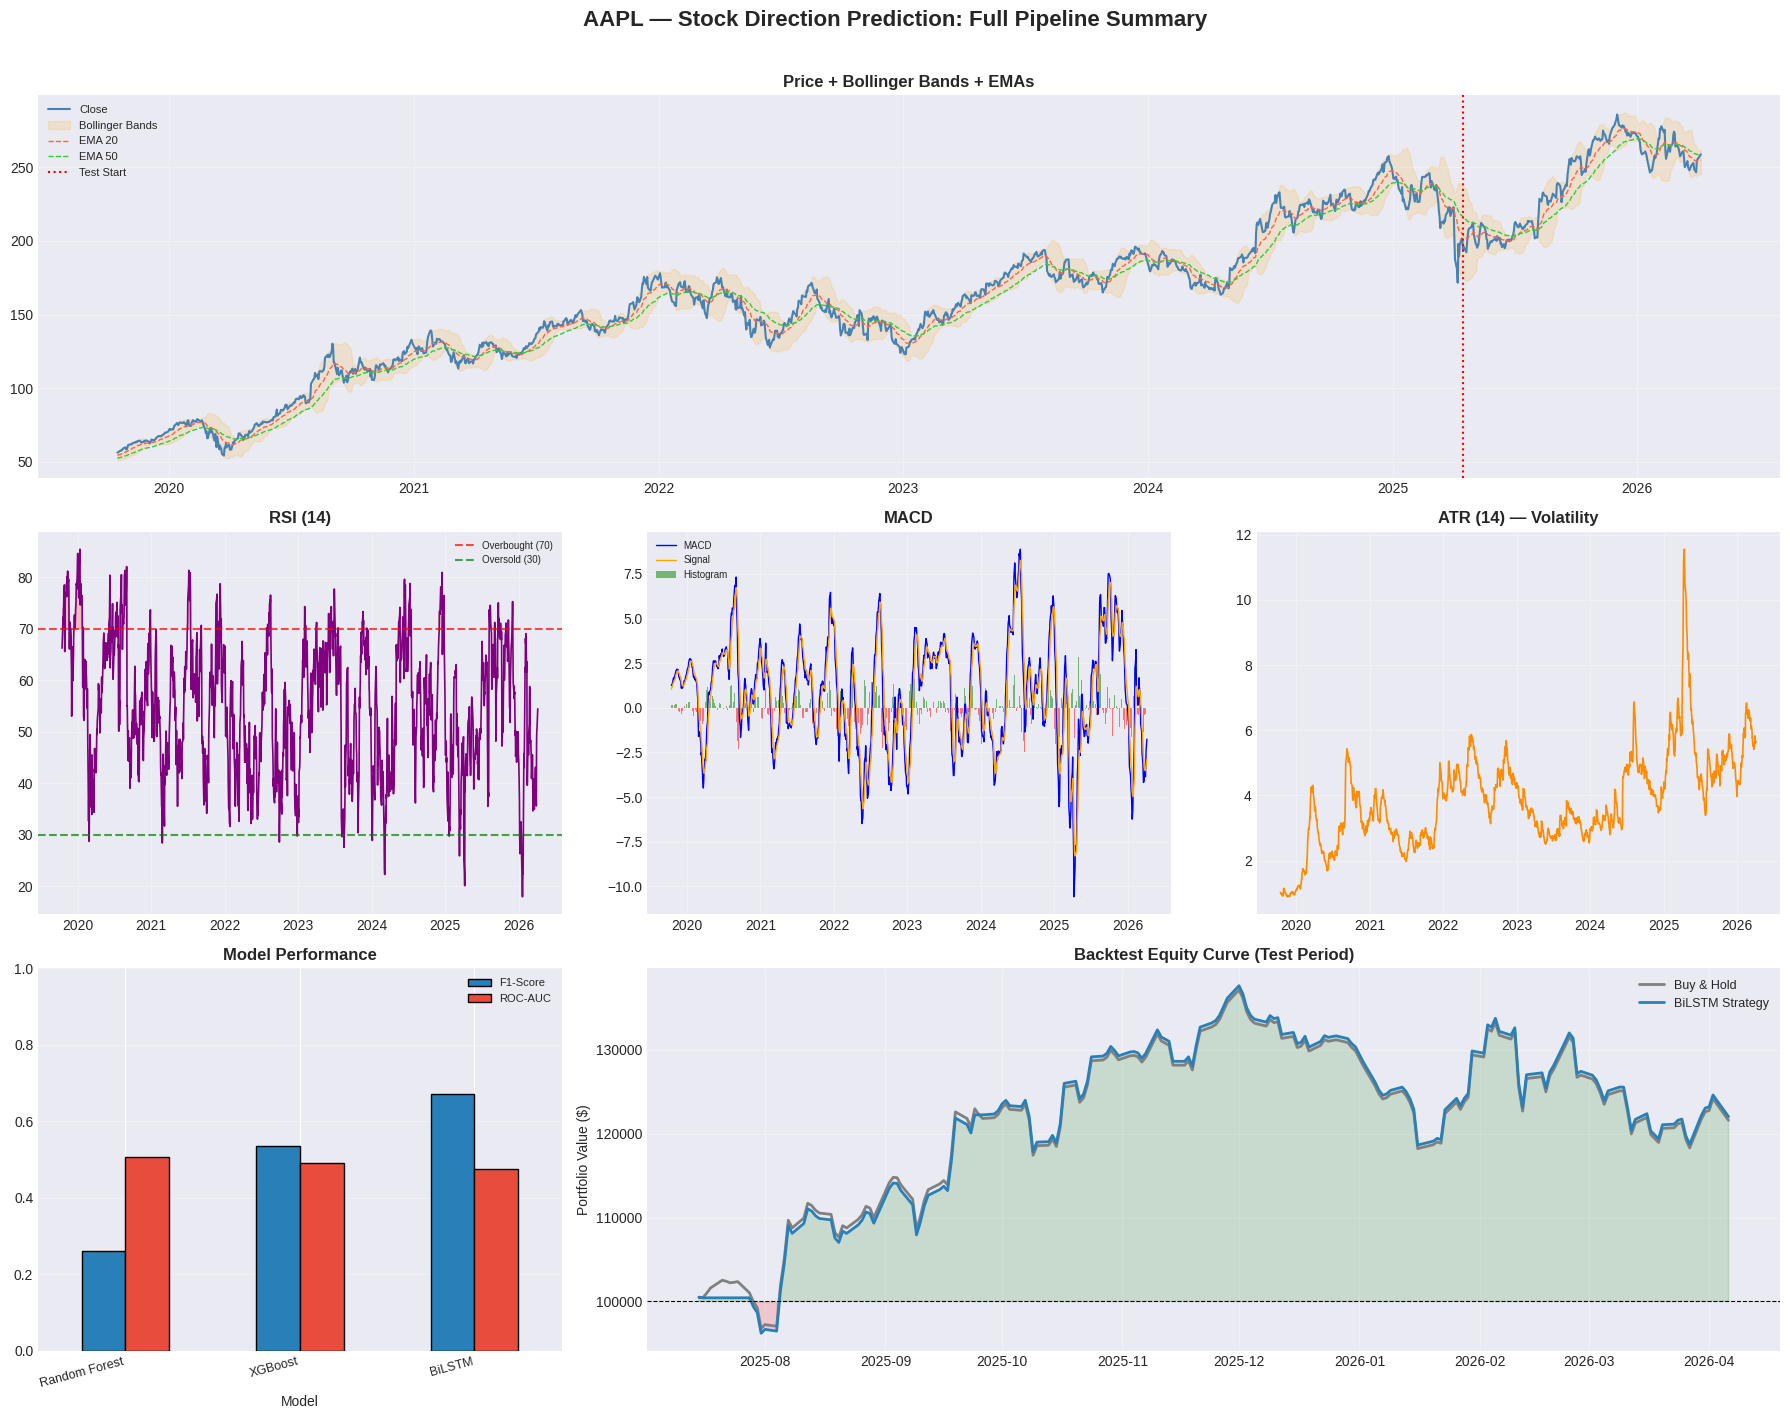


   PIPELINE COMPLETE — ALL STAGES FINISHED
  Ticker           : AAPL
  Features Built   : 85
  Best Model       : BiLSTM
  Next Day Signal  :  UP  (57.6% confidence)
  Est. Next Close  : $255.91

  💾 Saved charts:
    • price_history.png
    • feature_distributions.png
    • correlation_heatmap.png
    • rf_feature_importance.png
    • bilstm_training_history.png
    • model_comparison.png
    • backtest_results.png
    • confusion_matrices.png
    • shap_summary.png
    • shap_waterfall.png
    • final_dashboard.png


In [15]:
# ============================================================
#  CELL 15 — Final Summary Dashboard
# ============================================================
# "A picture is worth a thousand words — and in quant finance,
#  worth considerably more if the Sharpe is above 1.0."
#                                  — Anonymous quant, unverified
#
# One last comprehensive dashboard bringing everything together.

fig = plt.figure(figsize=(18, 14))
fig.suptitle(f'{TICKER} — Stock Direction Prediction: Full Pipeline Summary',
             fontsize=16, fontweight='bold', y=1.01)

# ── Top Row: Price history ────────────────────────────────
ax1 = fig.add_subplot(3, 3, (1, 3))  # Span full top row
ax1.plot(df.index, df['Close'], color='steelblue', lw=1.5, label='Close')
ax1.fill_between(df.index, df['bb_lower'], df['bb_upper'],
                 alpha=0.15, color='orange', label='Bollinger Bands')
ax1.plot(df.index, df['ema_20'],  color='tomato',     lw=1, linestyle='--', label='EMA 20')
ax1.plot(df.index, df['ema_50'],  color='limegreen',  lw=1, linestyle='--', label='EMA 50')
test_start_date = dates_test[0]
ax1.axvline(test_start_date, color='red', linewidth=1.5, linestyle=':', label='Test Start')
ax1.set_title('Price + Bollinger Bands + EMAs', fontweight='bold')
ax1.legend(fontsize=8)
ax1.grid(True, alpha=0.3)

# ── Middle Row ────────────────────────────────────────────
# RSI
ax2 = fig.add_subplot(3, 3, 4)
ax2.plot(df.index, df['rsi_14'], color='purple', lw=1.2)
ax2.axhline(70, color='red',   linestyle='--', alpha=0.7, label='Overbought (70)')
ax2.axhline(30, color='green', linestyle='--', alpha=0.7, label='Oversold (30)')
ax2.fill_between(df.index, 30, df['rsi_14'], where=df['rsi_14'] < 30, alpha=0.2, color='green')
ax2.fill_between(df.index, 70, df['rsi_14'], where=df['rsi_14'] > 70, alpha=0.2, color='red')
ax2.set_title('RSI (14)', fontweight='bold'); ax2.legend(fontsize=7); ax2.grid(True, alpha=0.3)

# MACD
ax3 = fig.add_subplot(3, 3, 5)
ax3.plot(df.index, df['macd'],        color='blue',   lw=1,   label='MACD')
ax3.plot(df.index, df['macd_signal'], color='orange', lw=1,   label='Signal')
ax3.bar(df.index, df['macd_diff'], color=np.where(df['macd_diff'] >= 0, 'green', 'red'),
        alpha=0.5, width=1, label='Histogram')
ax3.set_title('MACD', fontweight='bold'); ax3.legend(fontsize=7); ax3.grid(True, alpha=0.3)

# ATR
ax4 = fig.add_subplot(3, 3, 6)
ax4.plot(df.index, df['atr_14'], color='darkorange', lw=1.2)
ax4.set_title('ATR (14) — Volatility', fontweight='bold'); ax4.grid(True, alpha=0.3)

# ── Bottom Row ────────────────────────────────────────────
# Model metrics bar
ax5 = fig.add_subplot(3, 3, 7)
comparison[['F1-Score', 'ROC-AUC']].plot(kind='bar', ax=ax5, color=['#2980b9', '#e74c3c'],
                                          edgecolor='black')
ax5.set_title('Model Performance', fontweight='bold')
ax5.set_xticklabels(comparison.index, rotation=15, ha='right', fontsize=9)
ax5.set_ylim(0, 1); ax5.legend(fontsize=8); ax5.grid(True, alpha=0.3, axis='y')

# Equity Curve (zoomed on test period)
ax6 = fig.add_subplot(3, 3, (8, 9))
ax6.plot(equity_bnh.index,   equity_bnh,   color='gray',  lw=2, label='Buy & Hold')
ax6.plot(equity_strat.index, equity_strat, color='#2980b9', lw=2, label=f'{BEST_MODEL} Strategy')
ax6.fill_between(equity_strat.index, INITIAL_CAPITAL, equity_strat,
                 where=equity_strat >= INITIAL_CAPITAL, alpha=0.15, color='green')
ax6.fill_between(equity_strat.index, INITIAL_CAPITAL, equity_strat,
                 where=equity_strat < INITIAL_CAPITAL, alpha=0.15, color='red')
ax6.axhline(INITIAL_CAPITAL, color='black', lw=0.8, linestyle='--')
ax6.set_title('Backtest Equity Curve (Test Period)', fontweight='bold')
ax6.set_ylabel('Portfolio Value ($)')
ax6.legend(fontsize=9); ax6.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('final_dashboard.png', dpi=150, bbox_inches='tight')
plt.show()

print("\n" + "="*58)
print("   PIPELINE COMPLETE — ALL STAGES FINISHED")
print("="*58)
print(f"  Ticker           : {TICKER}")
print(f"  Features Built   : {len(FEATURE_COLS)}")
print(f"  Best Model       : {BEST_MODEL}")
print(f"  Next Day Signal  : {ensemble_dir}  ({ensemble_conf*100:.1f}% confidence)")
print(f"  Est. Next Close  : ${estimated_price:.2f}")
print("="*58)
print()
print("  💾 Saved charts:")
for fname in ['price_history', 'feature_distributions', 'correlation_heatmap',
              'rf_feature_importance', 'bilstm_training_history',
              'model_comparison', 'backtest_results', 'confusion_matrices',
              'shap_summary', 'shap_waterfall', 'final_dashboard']:
    print(f"    • {fname}.png")